In [1]:
import pandas as pd
import numpy as np
import heapq
from scipy.stats import chi2_contingency

In [2]:
df = pd.read_excel('dados/base_analise.xlsx')
sinan = pd.read_parquet('dados/2_df_recodificado.parquet')
sinan = sinan[sinan['ANO'].isin(range(2019,2025))]

## 1. Caracterização epidemiológica do escorpionismo
### Parte 1
1.1 Total de acidentes escorpiônicos no período de 2019–2024.  
1.2. Distribuição anual dos casos.  
1.3 Incidência média anual por 100.000 habitantes.  
1.4 Distribuição dos casos segundo faixas etárias de interesse.  
1.5 Número e proporção de casos MG segundo a definição operacional.  
1.6 Numero e proporção de MG ate 10 anos entre o total MG.  
1.7 Numero e proporção de MG ate 11A59 anos entre o total MG.  
1.8 Numero e proporção de MG 60+ entre o total MG.  
1.9 Numero de óbitos por ano de ocorrência.  
1.10 Numero de óbitos e prop. em relação ao total de casos.  
1.11 Num. e prop obitos 10 anos em relacao ao total obitos.  
1.12 Num. e prop obitos 11 a 59 anos em relacao ao total obitos.  
1.13 Num. e prop obitos 60+ em relacao ao total obitos.  
1.14 Tabela. Casos, obitos e proporções MG por região.

In [3]:
# Parte 1
print(
      '---------------------------------------------------------------------------- \n',
      '1.1 Total de acidentes entre 2019 e 2024:', df['TOTAL_CASOS'].sum(), '\n\n',

      
      '---------------------------------------------------------------------------- \n'
      '1.2 Distribuição anual dos casos:', sinan['ANO'].value_counts(), '\n\n',


      '---------------------------------------------------------------------------- \n'
      '1.3 Incidência média anual por 100 mil hab.:', df['INC_MEDIA_ANUAL'].describe(), '\n\n',


      '---------------------------------------------------------------------------- \n'
      '1.4 Distribuição dos casos por faixa etária:', '\n\n',
      'Total até 10 anos:', df['TOTAL_10A'].sum(), f"({df['TOTAL_10A'].sum() / df['TOTAL_CASOS'].sum()*100:.1f}%)", '\n',

      'Total de 11 a 59  anos:', df['TOTAL_11A59'].sum(), f"({df['TOTAL_11A59'].sum() / df['TOTAL_CASOS'].sum()*100:.1f}%)" '\n',

      'Total 60+:', df['TOTAL_60'].sum(),  f"({df['TOTAL_60'].sum() / df['TOTAL_CASOS'].sum()*100:.1f}%)" '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.5 Numero e proporção de casos MG:', df['MG'].sum(), f"({df['MG'].sum() / df['TOTAL_CASOS'].sum() * 100:.1f}%)", '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.6 Numero e proporção de MG ate 10 anos entre o total MG:', df['MG_10'].sum(), f"({df['MG_10'].sum()/df['MG'].sum()*100:.1f}%)", '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.7 Numero e proporção de MG ate 11A59 anos entre o total MG:', df['MG_11A59'].sum(), f"({df['MG_11A59'].sum()/df['MG'].sum()*100:.1f}%)", '\n\n',
      
      '---------------------------------------------------------------------------- \n',
      '1.8 Numero e proporção de MG 60+ entre o total MG:', df['MG_60'].sum(), f"({df['MG_60'].sum()/df['MG'].sum()*100:.1f}%)", '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.9 Numero de óbitos por ano de ocorrência:','\n', sinan[sinan['EVOLUCAO']=='Obito por ap'].groupby('ANO').size(), '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.10 Numero de óbitos e prop. em relação ao total de casos:', df['OBITOS'].sum(), f"({df['OBITOS'].sum()/df['TOTAL_CASOS'].sum()*100:.3f}%)", '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.11 Num. e prop obitos 10 anos em relacao ao total obitos:', df['OBITOS_10'].sum(), f"({df['OBITOS_10'].sum()/df['OBITOS'].sum()*100:.1f}%)", '\n\n',


      '---------------------------------------------------------------------------- \n',
      '1.12 Num. e prop obitos 11 a 59 anos em relacao ao total obitos:', df['OBITOS_11A59'].sum(), f"({df['OBITOS_11A59'].sum()/df['OBITOS'].sum()*100:.1f}%)", '\n\n',
      
      
      '---------------------------------------------------------------------------- \n',
      '1.13 Num. e prop obitos 60+ em relacao ao total obitos:', df['OBITOS_60'].sum(), f"({df['OBITOS_60'].sum()/df['OBITOS'].sum()*100:.1f}%)"

      )



---------------------------------------------------------------------------- 
 1.1 Total de acidentes entre 2019 e 2024: 239086 

 ---------------------------------------------------------------------------- 
1.2 Distribuição anual dos casos: ANO
2023    50125
2022    43619
2024    42148
2020    35275
2021    34437
2019    33484
Name: count, dtype: int64 

 ---------------------------------------------------------------------------- 
1.3 Incidência média anual por 100 mil hab.: count     645.000000
mean      295.713442
std       306.888537
min         0.000000
25%        50.795801
50%       192.607163
75%       445.729430
max      1590.079874
Name: INC_MEDIA_ANUAL, dtype: float64 

 ---------------------------------------------------------------------------- 
1.4 Distribuição dos casos por faixa etária: 

 Total até 10 anos: 22610 (9.5%) 
 Total de 11 a 59  anos: 166395 (69.6%)
 Total 60+: 50081 (20.9%)

 ---------------------------------------------------------------------------- 
 1.

In [4]:
# 1.14 Tabela. Casos, obitos e proporções MG por região 

import pandas as pd

# ============================================================
# TABELA EPIDEMIOLÓGICA POR REGIÃO
# ============================================================

# 1. Agregação regional
tabela_regiao = (
    df
    .groupby("REGIAO", as_index=False)
    .agg(
        POPULACAO=("POP_GERAL", "sum"),
        CASOS=("TOTAL_CASOS", "sum"),
        MG_10=("MG_10", "sum"),
        MG=("MG", "sum"),
        OBITOS=("OBITOS", "sum")
    )
)

# 2. Linha total do Estado
total_estado = pd.DataFrame({
    "REGIAO": ["Estado de São Paulo"],
    "POPULACAO": [df["POP_GERAL"].sum()],
    "CASOS": [df["TOTAL_CASOS"].sum()],
    "MG_10": [df["MG_10"].sum()],
    "MG": [df["MG"].sum()],
    "OBITOS": [df["OBITOS"].sum()]
})

# 3. Acrescentar o total às regiões e calcular os indicadores
tabela_regiao = (
    pd.concat(
        [tabela_regiao, total_estado],
        ignore_index=True
    )
    .assign(
        INC_MEDIA_ANUAL=lambda x:
            x["CASOS"] / (x["POPULACAO"] * 6) * 100000,

        ATE_MG_10_N_PCT=lambda x:
            x["MG_10"].astype(str) + " (" +
            (x["MG_10"] / x["MG"] * 100)
            .round(1).astype(str) + "%)",

        MG_N_PCT=lambda x:
            x["MG"].astype(str) + " (" +
            (x["MG"] / x["CASOS"] * 100)
            .round(1).astype(str) + "%)",

        OBITOS_N_LET=lambda x:
            x["OBITOS"].astype(str) + " (" +
            (x["OBITOS"] / x["CASOS"] * 100)
            .round(3).astype(str) + "%)"
    )
    [[
        "REGIAO",
        "POPULACAO",
        "CASOS",
        "INC_MEDIA_ANUAL",
        "ATE_MG_10_N_PCT",
        "MG_N_PCT",
        "OBITOS_N_LET"
    ]]
    .round({
        "INC_MEDIA_ANUAL": 1
    })
)

tabela_regiao.to_excel(r'resultados/tabela_regiao_epidemio.xlsx')

# tabela_regiao


## 2. Caracterização da rede PESA
2.1 Número e proporção de muni com PESA.  
2.2 Número e proporção de muni sem PESA
2.3 Proporção de muni com PESA Escorpionismo.  
2.4 Descritivo: número de Pesa por município com acesso local.  
2.5 Nomes dos Municípios com mais de 1 PESA
2.6 Distribuição acidentes entre municípios com e sem PESA  
2.7 Distribuição acidentes MG entre municípios com e sem PESA.  
2.8 Proporção de MG em municípios com e sem Pesa.  
2.9 Proporção de casos em municípios com e sem Pesa.  


In [5]:
# Parte 1 - Caracterização da rede PESA
print(
    '---------------------------------------------------------------------------- \n',
    f"2.1 Número e proporção de muni com PESA: {df[df['ACESSO_LOCAL']==1].shape[0]} ({round((df[df['ACESSO_LOCAL']==1].shape[0] / 645 * 100), 1)}%)", 
    '\n\n',
    
    '---------------------------------------------------------------------------- \n',
    f"2.2 Número e proporção de muni sem PESA: {df[df['ACESSO_LOCAL']==0].shape[0]} ({round((df[df['ACESSO_LOCAL']==0].shape[0] / 645 * 100), 1)}%)",
    '\n\n',

    '---------------------------------------------------------------------------- \n',
    f"2.3 Proporção de muni com PESA Escorp: {df[df['ACESSO_LOCAL']==1].shape[0]} ({round((df[df['ACESSO_LOCAL']==1].shape[0] / 242 * 100), 1)}%)",
    '\n\n',

    '---------------------------------------------------------------------------- \n',
    f"2.4 Descritivo: número de Pesa por município com acesso local: {df.loc[df['ACESSO_LOCAL']==1,['N_PESA']].describe().round(1)}",
    '\n\n',

    f"2.5 Municípios com mais de 1 PESA: {df.loc[(df['ACESSO_LOCAL']==1) & (df['N_PESA']>1),['MUNI','N_PESA']].sort_values('N_PESA', ascending=False)}",
    '\n\n',

    '---------------------------------------------------------------------------- \n',
    f"2.6 Distribuição acidentes entre municípios com e sem PESA: \n {df.groupby('ACESSO_LOCAL')['TOTAL_CASOS'].describe().T}",
    '\n\n',

    '---------------------------------------------------------------------------- \n',
    f"2.7 Distribuição acidentes MG entre municípios com e sem PESA: \n {df.groupby('ACESSO_LOCAL')['MG'].describe().T}",
    '\n\n',

    '---------------------------------------------------------------------------- \n',
    '2.8 Proporção de casos em municípios com e sem Pesa:', '\n',
     'Muni com Pesa:', (df.loc[df['ACESSO_LOCAL']==1,'TOTAL_CASOS'].sum() / df['TOTAL_CASOS'].sum() * 100).round(1),'\n',
     'Muni sem Pesa:', (df.loc[df['ACESSO_LOCAL']==0,'TOTAL_CASOS'].sum() / df['TOTAL_CASOS'].sum() * 100).round(1),
     '\n\n',

    
    '---------------------------------------------------------------------------- \n',    
    '2.9 Proporção de MG em municípios com e sem Pesa:', '\n',
    'MG em Muni com Pesa:', (df.loc[df['ACESSO_LOCAL']==1,'MG'].sum() / df['MG'].sum() * 100).round(1),'\n',
    'MG em Muni sem Pesa:', (df.loc[df['ACESSO_LOCAL']==0,'MG'].sum() / df['MG'].sum() * 100).round(1)
)




---------------------------------------------------------------------------- 
 2.1 Número e proporção de muni com PESA: 220 (34.1%) 

 ---------------------------------------------------------------------------- 
 2.2 Número e proporção de muni sem PESA: 425 (65.9%) 

 ---------------------------------------------------------------------------- 
 2.3 Proporção de muni com PESA Escorp: 220 (90.9%) 

 ---------------------------------------------------------------------------- 
 2.4 Descritivo: número de Pesa por município com acesso local:        N_PESA
count   220.0
mean      1.1
std       0.6
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       7.0 

 2.5 Municípios com mais de 1 PESA:                       MUNI  N_PESA
611              SAO PAULO       7
635  SAO JOSE DO RIO PRETO       5
619    SAO JOSE DOS CAMPOS       4
612              GUARULHOS       2
614               CAMPINAS       2
613                  BAURU       2
616                MARILIA       2
615        

In [6]:
# Tabela 2. Total de casos entre municípios com e sem PESA
describe_total_mg = df.groupby('ACESSO_LOCAL')['MG'].describe().round(1).T
describe_total_casos = df.groupby('ACESSO_LOCAL')['TOTAL_CASOS'].describe().round(1).T

pd.concat([describe_total_mg, describe_total_casos], axis=1).to_excel('resultados/describe_casos_por_tipo_acesso.xlsx')

In [7]:
# População por acesso local
print(df.groupby('ACESSO_LOCAL')['POP_GERAL'].sum())

ACESSO_LOCAL
0    10974105
1    34762873
Name: POP_GERAL, dtype: int64


In [8]:
# Taxa de indicência acumulada por tipo de acesso
print(
    'Tx Incidencia em municipios SEM acesso local:', (df.loc[df['ACESSO_LOCAL']==0, 'TOTAL_CASOS'].sum()/df.loc[df['ACESSO_LOCAL']==0, 'POP_GERAL'].sum()*100000).round(1), '\n',
    'Tx Incidencia em municipios COM acesso local:', (df.loc[df['ACESSO_LOCAL']==1, 'TOTAL_CASOS'].sum()/df.loc[df['ACESSO_LOCAL']==1, 'POP_GERAL'].sum()*100000).round(1)
    )

Tx Incidencia em municipios SEM acesso local: 640.5 
 Tx Incidencia em municipios COM acesso local: 485.6


# 3. Acessibilidade geográfica aos PESA
* Descritivo do tempo estimado até o PESA
* Categorias de tempo (menor e maior 50min).
* Municipios com tempo superior a 50 min por região.
* População residente em cada estrato de acessibilidade.
* Número de acidentes e MG em cada estrato de tempo.
* Identificação dos municípios/regiões com maiores tempos estimados.
* Produto principal: Mapa do tempo estimado de deslocamento até o PESA de referência.


In [9]:
print(
    '3.1 Descritivo do tempo até o PESA:', df.loc[df['ACESSO_LOCAL']==0, 'TEMPO'].describe(), '\n\n',
    
    
    '3.2 Categorias de tempo (menor e maior 50min):', '\n',
    (df.loc[df['ACESSO_LOCAL']==0, 'TEMPO_50'].value_counts().reset_index(name='N')
     .assign(PERCENT = lambda x: x['N']/x['N'].sum()*100
             ).round(1)
             ), '\n\n',

    'Municipios com tempo superior a 50 min: \n',
    df.loc[(df['ACESSO_LOCAL']==0) & (df['TEMPO_50']=='>50 min'),['REGIAO', 'PESA','MUNI', 'TEMPO']].sort_values(by='REGIAO').round(1), '\n\n',

'3.3 Municipios com tempo superior a 50 min por região: \n',
df.loc[(df['ACESSO_LOCAL'] == 0) & (df['TEMPO_50'] == '>50 min'), ['REGIAO', 'PESA', 'MUNI', 'TEMPO']].sort_values(by='REGIAO').round(1).groupby('REGIAO').agg(
    MUNI=('MUNI', 'count'),
    MEDIANA_TEMPO=('TEMPO', 'median')
)
)

3.1 Descritivo do tempo até o PESA: count    425.000000
mean      27.376395
std       11.996764
min        6.800000
25%       19.000000
50%       25.200000
75%       34.300000
max       70.800000
Name: TEMPO, dtype: float64 

 3.2 Categorias de tempo (menor e maior 50min): 
   TEMPO_50    N  PERCENT
0  ≤50 min  404     95.1
1  >50 min   21      4.9 

 Municipios com tempo superior a 50 min: 
                     REGIAO           PESA                    MUNI  TEMPO
31              ARARAQUARA     SAO CARLOS                 DOURADO   54.1
63                   ASSIS       OURINHOS                 TIMBURI   57.5
67                BARRETOS       BARRETOS               JABORANDI   57.6
101                  BAURU           LINS                     URU   56.3
103               BOTUCATU       BOTUCATU                 ANHEMBI   54.9
117               BOTUCATU       BOTUCATU               PORANGABA   63.5
123               BOTUCATU       BOTUCATU          TORRE DE PEDRA   58.2
141               CA

In [54]:
reg = df.groupby('REGIAO')['MUNI'].size().reset_index(name='MUNI')
semPesaReg = df[df['ACESSO_LOCAL']==0].groupby('REGIAO')['MUNI'].size().reset_index(name='SEM_PESA')
popReg = df.groupby('REGIAO')['POP_GERAL'].sum()
popRegSemPesa = df[df['ACESSO_LOCAL']==0].groupby('REGIAO')['POP_GERAL'].sum().reset_index(name='POP_SEM_PESA')
medianReg = df.groupby('REGIAO')['TEMPO'].median().reset_index(name='MEDIAN_TEMPO')
muniMais50 = df[df['TEMPO_50']=='>50 min'].groupby('REGIAO').size().reset_index(name='N_MUNI_MAIS50').round(0)
nPesa = df.groupby('REGIAO')['N_PESA'].sum().reset_index(name='N_PESA')

colunas = [semPesaReg,popReg,popRegSemPesa,medianReg,muniMais50,nPesa]
 
for i in colunas:
    reg = reg.merge(
        i,
        on='REGIAO',
        how='left'
).round(0)





# Cria uma linha de soma para as colunas numéricas e junta no DataFrame original
reg = pd.concat([reg, reg.sum(numeric_only=True).to_frame().T.assign(REGIAO='ESTADO')], ignore_index=True)


# Percentuais
reg = reg.assign(
    PERCENT_SEM_PESA = lambda x: (x['SEM_PESA']/x['MUNI']*100).round(1),
    PERCENT_POP_SEM_PESA = lambda x: (x['POP_SEM_PESA']/x['POP_GERAL']*100).round(1),
    PERCENT_MUNI_MAIS50 = lambda x: (x['N_MUNI_MAIS50']/x['SEM_PESA']*100).round(1),
    RAZAO_PESA_MUNI = lambda x: (x['MUNI'] / x['N_PESA']).round(1)
)

reg = reg.fillna(0)

# Muni sem PESA e percentual sem PESA
reg['SEM_PESA_N%'] = reg['SEM_PESA'].astype(str) + ' (' + reg['PERCENT_SEM_PESA'].astype(str) + '%)'

# Pop sem PESA e percentual de pop sem PESA
reg['POP_SEM_PESA_N%'] = reg['POP_SEM_PESA'].astype(str) + ' (' + reg['PERCENT_POP_SEM_PESA'].astype(str) + '%)'

reg.head()

reg = reg.drop(columns=['SEM_PESA','POP_SEM_PESA','PERCENT_SEM_PESA','PERCENT_POP_SEM_PESA','PERCENT_MUNI_MAIS50'])

reg

,REGIAO,MUNI,POP_GERAL,MEDIAN_TEMPO,N_MUNI_MAIS50,N_PESA,RAZAO_PESA_MUNI,SEM_PESA_N%,POP_SEM_PESA_N%
0,ARACATUBA,40.0,778764.0,22.0,0.0,15.0,2.7,25.0 (62.5%),114881.0 (14.8%)
1,ARARAQUARA,24.0,1017893.0,28.0,1.0,7.0,3.4,17.0 (70.8%),217456.0 (21.4%)
2,ASSIS,25.0,477766.0,26.0,1.0,4.0,6.2,21.0 (84.0%),175962.0 (36.8%)
3,BARRETOS,18.0,438357.0,30.0,1.0,6.0,3.0,12.0 (66.7%),112456.0 (25.7%)
4,BAURU,38.0,1154860.0,24.0,1.0,18.0,2.1,21.0 (55.3%),220648.0 (19.1%)
5,BOTUCATU,30.0,618794.0,32.0,3.0,8.0,3.8,22.0 (73.3%),241433.0 (39.0%)
6,CAMPINAS,42.0,4733979.0,24.0,1.0,15.0,2.8,29.0 (69.0%),1416618.0 (29.9%)
7,CARAGUATATUBA,4.0,349708.0,0.0,0.0,5.0,0.8,0.0 (0.0%),0.0 (0.0%)
8,FRANCA,22.0,700936.0,18.0,0.0,9.0,2.4,13.0 (59.1%),110316.0 (15.7%)
9,FRANCO DA ROCHA,5.0,605130.0,29.0,0.0,3.0,1.7,2.0 (40.0%),190247.0 (31.4%)


0       114881.0 (14.8%)
1       217456.0 (21.4%)
2       175962.0 (36.8%)
3       112456.0 (25.7%)
4       220648.0 (19.1%)
5       241433.0 (39.0%)
6      1416618.0 (29.9%)
7             0.0 (0.0%)
8       110316.0 (15.7%)
9       190247.0 (31.4%)
10       28146.0 (10.0%)
11      113477.0 (40.3%)
12      303319.0 (46.3%)
13      949087.0 (31.5%)
14     2182908.0 (69.3%)
15      234429.0 (14.7%)
16      134438.0 (28.4%)
17       50114.0 (17.2%)
18            0.0 (0.0%)
19      445045.0 (29.6%)
20     1512800.0 (54.3%)
21      341693.0 (18.5%)
22      192909.0 (23.4%)
23      474573.0 (34.2%)
24        31412.0 (2.8%)
25            0.0 (0.0%)
26      964287.0 (41.5%)
27      215451.0 (19.5%)
28    10974105.0 (24.0%)
dtype: str

# 4. Sobreposição entre carga epidemiológica e acessibilidade
* Construção da matriz bivariada Carga MG por Tempo 50.
* Para cada perfil:
    * número de municípios;
    * população;
    * total de acidentes;
    * número de MG;
    * participação na carga de MG.
* Identificação dos municípios classificados simultaneamente como maior carga de MG + maior tempo de deslocamento.
* Avaliação estatística da sobreposição:
* qui-quadrado de Pearson;
* V de Cramér;
* frequências observadas e esperadas;
* resíduos padronizados.
* Interpretação como sobreposição territorial entre carga e acessibilidade, e não como efeito do tempo sobre a gravidade.
* Produto principal: Mapa bivariado carga de MG × tempo de acesso, acompanhado da matriz 3 × 3.


In [12]:
# Matriz de carga epidemiologica
pd.crosstab(df['TEMPO_50'], df['CARGA_MG'], margins=True, margins_name='Total')


CARGA_MG,Alta,Baixa,Intermediária,Total
TEMPO_50,,,,
>50 min,5,13,3,21
≤50 min,134,142,128,404
Total,139,155,131,425


In [13]:
# Municípios com sobrecarga epidemiológica e tempo superior a 50 min
display(
'Carga alta e >50min',
df.loc[(df['TEMPO_50']=='>50 min') & (df['CARGA_MG']=='Alta'),['REGIAO','PESA','MUNI','TEMPO']],


'Carga intermediária e >50min', 
df.loc[(df['TEMPO_50']=='>50 min') & (df['CARGA_MG']=='Intermediária'),['REGIAO','PESA','MUNI','TEMPO']],


'Carga baixa e >50min', 
df.loc[(df['TEMPO_50']=='>50 min') & (df['CARGA_MG']=='Baixa'),['REGIAO','PESA','MUNI','TEMPO']]

)

'Carga alta e >50min'

,REGIAO,PESA,MUNI,TEMPO
67,BARRETOS,BARRETOS,JABORANDI,57.600000
103,BOTUCATU,BOTUCATU,ANHEMBI,54.900000
328,SAO JOSE DO RIO PRETO,CATANDUVA,IRAPUA,60.700000
344,SAO JOSE DO RIO PRETO,NOVA GRANADA,PAULO DE FARIA,57.900000
421,MARILIA,MARILIA,GUARANTA,55.758065


'Carga intermediária e >50min'

,REGIAO,PESA,MUNI,TEMPO
117,BOTUCATU,BOTUCATU,PORANGABA,63.500000
415,MARILIA,MARILIA,CAMPOS NOVOS PAULISTA,53.842857
429,MARILIA,MARILIA,UBIRAJARA,61.650000


'Carga baixa e >50min'

,REGIAO,PESA,MUNI,TEMPO
31,ARARAQUARA,SAO CARLOS,DOURADO,54.1
63,ASSIS,OURINHOS,TIMBURI,57.5
101,BAURU,LINS,URU,56.3
123,BOTUCATU,BOTUCATU,TORRE DE PEDRA,58.2
141,CAMPINAS,SOCORRO,PIRACAIA,70.8
162,ITAPEVA,ITAPEVA,BOM SUCESSO DE ITARARE,60.2
165,ITAPEVA,APIAI,RIBEIRA,59.1
166,ITAPEVA,ITARARE,RIVERSUL,54.0
194,JALES,FERNANDOPOLIS,SAO JOAO DE IRACEMA,51.7
326,SAO JOSE DO RIO PRETO,VOTUPORANGA,GASTAO VIDIGAL,56.5


In [14]:
tabCargaTempo = pd.crosstab(df['TEMPO_50'], df['CARGA_MG'])
chi, pvalor, graus_lib, esperados = chi2_contingency(tabCargaTempo)

print(f"Estatística Qui-Quadrado: {chi:.4f}", '\n',
      f"p-valor: {pvalor:.4f}", '\n',
      f"Graus de Liberdade: {graus_lib}", '\n',
      "Frequências Esperadas:\n", esperados)

Estatística Qui-Quadrado: 6.4133 
 p-valor: 0.0405 
 Graus de Liberdade: 2 
 Frequências Esperadas:
 [[  6.86823529   7.65882353   6.47294118]
 [132.13176471 147.34117647 124.52705882]]


In [15]:

df.select_dtypes(include=['float', 'number'])

,Unnamed: 0,ACESSO_LOCAL,MULTIPLO_PESA,LAT_MUNI,LON_MUNI,LAT_PESA,LON_PESA,DISTANCIA,TEMPO,IBGE,...,PROP_CASOS_0A10,PROP_CASOS_60MAIS,TAXA_MG_100MIL,CLASS_IG,SORO_IG,EVOL_IG,PROP_CLASS_IGN,PROP_SORO_IGN,PROP_EVOL_IGN,BAIXO_N
0,0,0,0,-21.582059,-50.166198,-21.416404,-50.064911,23.5,25.7,350110,...,0.0542,0.3797,45.67,1,1,0,0.0034,0.0034,0.0000,0
1,1,0,0,-21.460333,-49.946516,-21.416404,-50.064911,14.1,15.9,350440,...,0.0694,0.2041,29.57,2,7,10,0.0082,0.0286,0.0408,0
2,2,0,0,-21.265661,-49.951816,-21.416404,-50.064911,26.7,22.8,350510,...,0.1057,0.2004,34.54,6,173,17,0.0132,0.3811,0.0374,0
3,3,0,0,-21.271572,-50.811723,-21.230655,-50.861195,9.5,12.8,350620,...,0.1084,0.1928,30.11,2,1,2,0.0241,0.0120,0.0241,0
4,4,0,0,-21.403962,-50.474640,-21.556698,-50.446533,21.6,19.8,350640,...,0.0654,0.3077,21.45,10,1,7,0.0385,0.0038,0.0269,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
640,640,0,0,0.000000,0.000000,0.000000,0.000000,27.3,37.0,352115,...,0.0843,0.2490,50.89,1,0,1,0.0040,0.0000,0.0040,0
641,641,0,0,0.000000,0.000000,0.000000,0.000000,32.4,35.0,353400,...,0.1473,0.1589,37.59,1,4,1,0.0039,0.0155,0.0039,0
642,642,1,1,0.000000,0.000000,0.000000,0.000000,NaN,NaN,353870,...,0.0955,0.1521,6.63,144,152,91,0.0179,0.0189,0.0113,0
643,643,0,0,0.000000,0.000000,0.000000,0.000000,16.4,22.0,354400,...,0.1477,0.1242,3.11,7,46,2,0.0235,0.1544,0.0067,0


In [16]:
dfNumber = df.select_dtypes(include=['float', 'number'])
dfNumber = dfNumber.iloc[:,7:50]



In [17]:
'''dfNumber = dfNumber[['DISTANCIA', 'TEMPO',  'POP10', 'MG_10', 'TOTAL_AMPOLAS', 'OBITOS', 'OBITOS_10','N_PESA', 'PROP_POP_0A10',
       'PROP_MG', 'INCID_MEDIA_GERAL','INCID_0A10','PROP_CASOS_0A10']]'''
matriz_cor = dfNumber.corr(method='pearson').round(1)

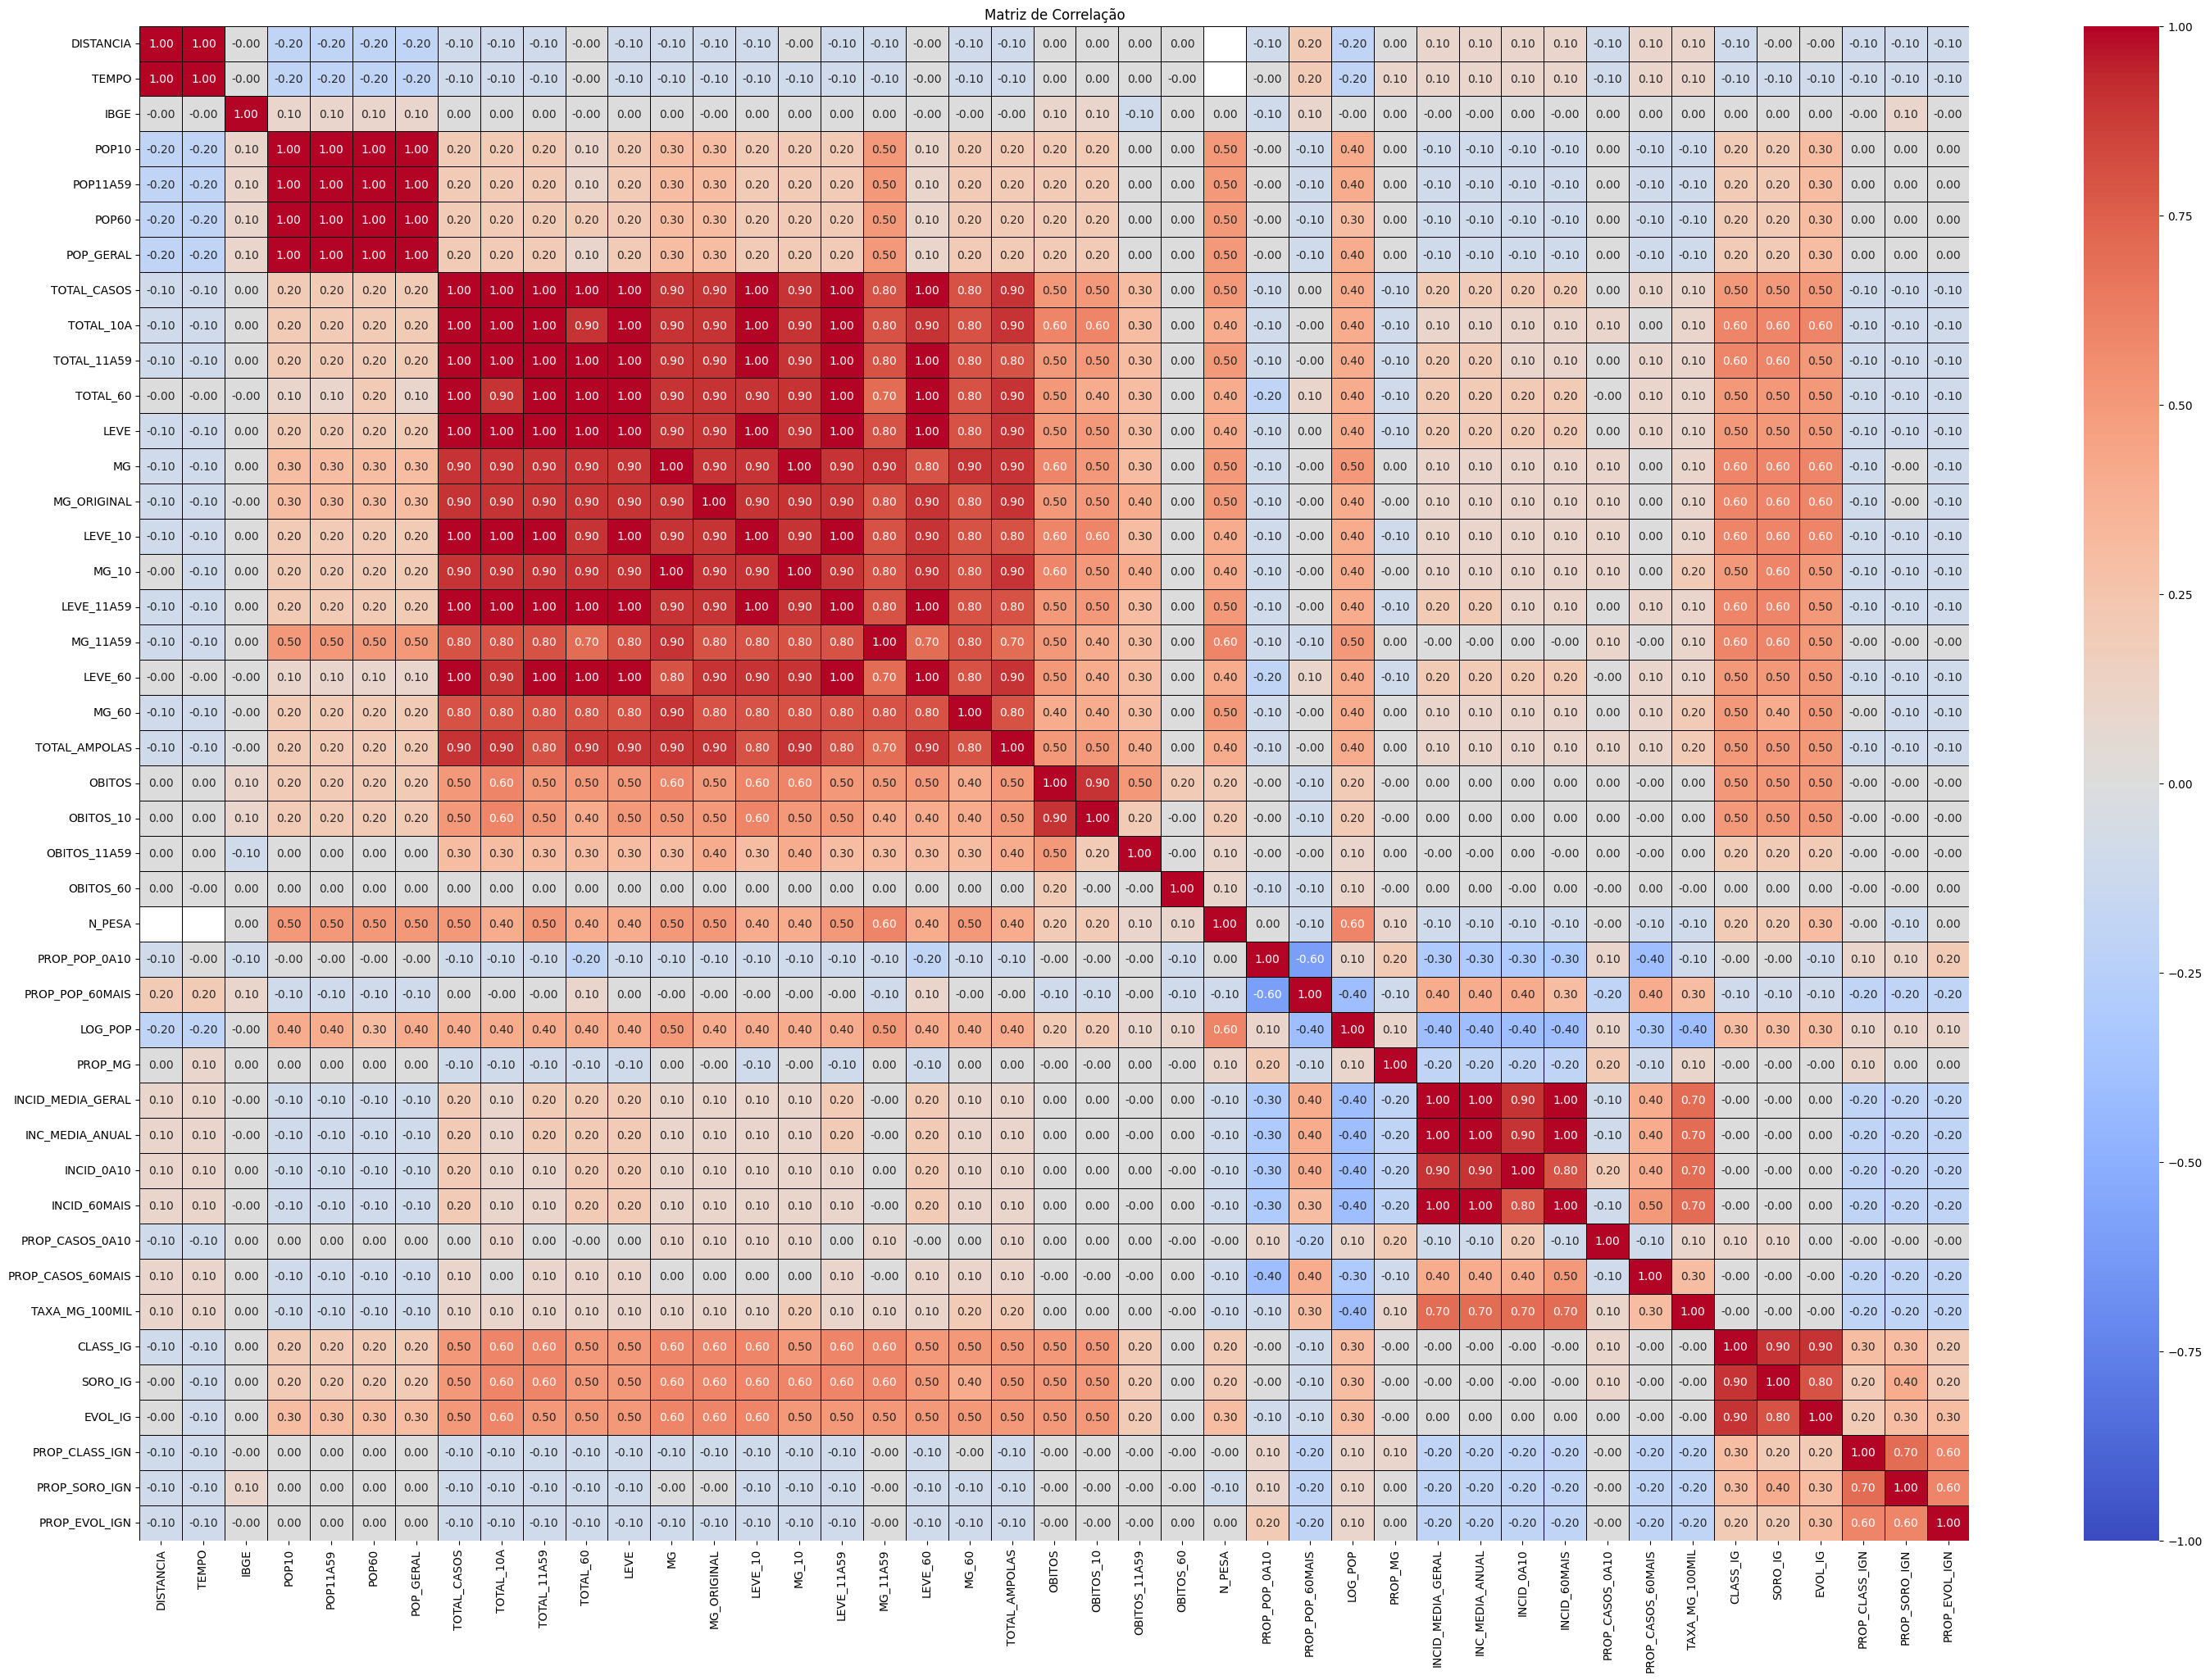

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(36 , 24))
sns.heatmap(matriz_cor, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=.5, linecolor='black')
plt.title('Matriz de Correlação')
plt.show()